<a href="https://colab.research.google.com/github/SAIPRANAV-7/Greeting_Card/blob/main/SmartBrief_NLP_AAT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import re
import math
import nltk
import numpy as np
import pandas as pd
import networkx as nx

from collections import Counter
from itertools import islice
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("SmartBrief libraries imported successfully!")

SmartBrief libraries imported successfully!


In [2]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

STOP_WORDS = set(stopwords.words("english"))

print("Language resources are ready!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


Language resources are ready!


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [3]:
%pip -q install datasets

In [4]:
from datasets import load_dataset

dataset = load_dataset(
    "abisee/cnn_dailymail",
    "3.0.0",
    split="test",
    streaming=True
)

samples = list(islice(dataset, 5))

print("Number of articles loaded:", len(samples))
print("Available fields:", samples[0].keys())
print("\nFirst article preview:\n")
print(samples[0]["article"][:1000])

print("\nReference summary:\n")
print(samples[0]["highlights"])

README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

Number of articles loaded: 5
Available fields: dict_keys(['article', 'highlights', 'id'])

First article preview:

(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes committed "in the occupied Palestinian territory, including East Jerusalem, since June 13, 2014." Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, paving the way for possible war crimes investigations against Israelis. As members of the court, Palestinians may be subject to counter-charges as well. Israel and the United States, neither of which is an ICC member, opposed the Palestini

In [5]:
article = samples[0]["article"]

sentences = sent_tokenize(article)

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

print("Original article length:", len(article.split()), "words")
print("Number of sentences:", len(sentences))

print("\nFirst 5 sentences:\n")

for i, sentence in enumerate(sentences[:5], start=1):
    print(f"{i}. {sentence}")

Original article length: 567 words
Number of sentences: 27

First 5 sentences:

1. (CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories.
2. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based.
3. The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes committed "in the occupied Palestinian territory, including East Jerusalem, since June 13, 2014."
4. Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, paving the way for possible war crimes investigations against Israelis.
5. As members of the court, Palestinians may be subject to counter-charges as well.


In [6]:
def tokenize_words(text):
    return re.findall(r"\b[a-z0-9]+\b", clean_text(text))

example_sentence = sentences[0]

all_words = tokenize_words(example_sentence)

meaningful_words = [
    word for word in all_words
    if word not in STOP_WORDS
]

print("Original sentence:")
print(example_sentence)

print("\nTokens:")
print(all_words)

print("\nTokens after stop-word removal:")
print(meaningful_words)

Original sentence:
(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories.

Tokens:
['cnn', 'the', 'palestinian', 'authority', 'officially', 'became', 'the', '123rd', 'member', 'of', 'the', 'international', 'criminal', 'court', 'on', 'wednesday', 'a', 'step', 'that', 'gives', 'the', 'court', 'jurisdiction', 'over', 'alleged', 'crimes', 'in', 'palestinian', 'territories']

Tokens after stop-word removal:
['cnn', 'palestinian', 'authority', 'officially', 'became', '123rd', 'member', 'international', 'criminal', 'court', 'wednesday', 'step', 'gives', 'court', 'jurisdiction', 'alleged', 'crimes', 'palestinian', 'territories']


In [7]:
all_article_words = []

for sentence in sentences:
    words = tokenize_words(sentence)
    all_article_words.extend(
        word for word in words
        if word not in STOP_WORDS
    )

word_frequencies = Counter(all_article_words)

print("Most frequent informative words:\n")

for word, count in word_frequencies.most_common(15):
    print(f"{word}: {count}")

Most frequent informative words:

icc: 10
said: 10
court: 9
palestine: 7
crimes: 6
state: 6
palestinian: 5
international: 4
palestinians: 4
statute: 4
war: 4
justice: 4
step: 3
alleged: 3
territories: 3


In [8]:
def frequency_summarizer(text, num_sentences=3):
    sentences = sent_tokenize(text)

    if not sentences:
        return ""

    words = []

    for sentence in sentences:
        words.extend(
            word for word in tokenize_words(sentence)
            if word not in STOP_WORDS
        )

    frequencies = Counter(words)

    max_frequency = max(frequencies.values(), default=1)

    normalized_frequencies = {
        word: count / max_frequency
        for word, count in frequencies.items()
    }

    scores = []

    for sentence in sentences:
        sentence_words = [
            word for word in tokenize_words(sentence)
            if word not in STOP_WORDS
        ]

        if not sentence_words:
            score = 0
        else:
            score = sum(
                normalized_frequencies.get(word, 0)
                for word in sentence_words
            ) / math.sqrt(len(sentence_words))

        scores.append(score)

    ranked_indices = sorted(
        range(len(sentences)),
        key=lambda i: scores[i],
        reverse=True
    )

    selected_indices = sorted(
        ranked_indices[:min(num_sentences, len(sentences))]
    )

    return " ".join(sentences[i] for i in selected_indices)


frequency_summary = frequency_summarizer(article, num_sentences=3)

print("FREQUENCY-BASED SUMMARY\n")
print(frequency_summary)

FREQUENCY-BASED SUMMARY

(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. "As Palestine formally becomes a State Party to the Rome Statute today, the world is also a step closer to ending a long era of impunity and injustice," he said, according to an ICC news release. "As we have said repeatedly, we do not believe that Palestine is a state and therefore we do not believe that it is eligible to join the ICC," the State Department said in a statement.


In [9]:
def textrank_summarizer(text, num_sentences=3):
    sentences = sent_tokenize(text)

    if not sentences:
        return ""

    if len(sentences) <= num_sentences:
        return " ".join(sentences)

    vectorizer = TfidfVectorizer(
        stop_words="english",
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b"
    )

    sentence_vectors = vectorizer.fit_transform(sentences)

    similarity_matrix = cosine_similarity(sentence_vectors)

    np.fill_diagonal(similarity_matrix, 0)

    graph = nx.from_numpy_array(similarity_matrix)

    scores = nx.pagerank(
        graph,
        weight="weight"
    )

    ranked_indices = sorted(
        scores,
        key=scores.get,
        reverse=True
    )

    selected_indices = sorted(
        ranked_indices[:min(num_sentences, len(sentences))]
    )

    return " ".join(sentences[i] for i in selected_indices)


textrank_summary = textrank_summarizer(article, num_sentences=3)

print("TEXTRANK SUMMARY\n")
print(textrank_summary)

TEXTRANK SUMMARY

(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. "As Palestine formally becomes a State Party to the Rome Statute today, the world is also a step closer to ending a long era of impunity and injustice," he said, according to an ICC news release. "As we have said repeatedly, we do not believe that Palestine is a state and therefore we do not believe that it is eligible to join the ICC," the State Department said in a statement.


In [10]:
from IPython.display import display, Markdown

display(Markdown("## Original Article"))
display(Markdown(article[:2500] + ("..." if len(article) > 2500 else "")))

display(Markdown("## Frequency-Based Summary"))
display(Markdown(frequency_summary))

display(Markdown("## TextRank Summary"))
display(Markdown(textrank_summary))

display(Markdown("## Human-Written Reference Summary"))
display(Markdown(samples[0]["highlights"]))

## Original Article

(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes committed "in the occupied Palestinian territory, including East Jerusalem, since June 13, 2014." Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, paving the way for possible war crimes investigations against Israelis. As members of the court, Palestinians may be subject to counter-charges as well. Israel and the United States, neither of which is an ICC member, opposed the Palestinians' efforts to join the body. But Palestinian Foreign Minister Riad al-Malki, speaking at Wednesday's ceremony, said it was a move toward greater justice. "As Palestine formally becomes a State Party to the Rome Statute today, the world is also a step closer to ending a long era of impunity and injustice," he said, according to an ICC news release. "Indeed, today brings us closer to our shared goals of justice and peace." Judge Kuniko Ozaki, a vice president of the ICC, said acceding to the treaty was just the first step for the Palestinians. "As the Rome Statute today enters into force for the State of Palestine, Palestine acquires all the rights as well as responsibilities that come with being a State Party to the Statute. These are substantive commitments, which cannot be taken lightly," she said. Rights group Human Rights Watch welcomed the development. "Governments seeking to penalize Palestine for joining the ICC should immediately end their pressure, and countries that support universal acceptance of the court's treaty should speak out to welcome its membership," said Balkees Jarrah, international justice counsel for the group. "What's objectionable is the attempts to undermine international justice, not Palestine's decision to join a treaty to which over 100 countries around the world are members." In January, when the preliminary ICC examination was opened, Israeli Prime Minister Benjamin Netanyahu described it as an outrage, saying the court was overstepping its boundaries. The United States also said it "strongly" disagreed with the court's decision. "As we have said repeatedl...

## Frequency-Based Summary

(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. "As Palestine formally becomes a State Party to the Rome Statute today, the world is also a step closer to ending a long era of impunity and injustice," he said, according to an ICC news release. "As we have said repeatedly, we do not believe that Palestine is a state and therefore we do not believe that it is eligible to join the ICC," the State Department said in a statement.

## TextRank Summary

(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. "As Palestine formally becomes a State Party to the Rome Statute today, the world is also a step closer to ending a long era of impunity and injustice," he said, according to an ICC news release. "As we have said repeatedly, we do not believe that Palestine is a state and therefore we do not believe that it is eligible to join the ICC," the State Department said in a statement.

## Human-Written Reference Summary

Membership gives the ICC jurisdiction over alleged crimes committed in Palestinian territories since last June .
Israel and the United States opposed the move, which could open the door to war crimes investigations against Israelis .

In [11]:
def get_tokens(text):
    return re.findall(r"\b[a-z0-9]+\b", text.lower())


def get_ngrams(tokens, n):
    return Counter(
        tuple(tokens[i:i+n])
        for i in range(len(tokens) - n + 1)
    )


def rouge_n(reference, generated, n=1):
    ref_tokens = get_tokens(reference)
    gen_tokens = get_tokens(generated)

    ref_ngrams = get_ngrams(ref_tokens, n)
    gen_ngrams = get_ngrams(gen_tokens, n)

    overlap = sum(
        (ref_ngrams & gen_ngrams).values()
    )

    total_ref = sum(ref_ngrams.values())
    total_gen = sum(gen_ngrams.values())

    recall = overlap / total_ref if total_ref else 0
    precision = overlap / total_gen if total_gen else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return f1


def lcs_length(a, b):
    previous = [0] * (len(b) + 1)

    for token_a in a:
        current = [0]

        for j, token_b in enumerate(b, start=1):
            if token_a == token_b:
                current.append(previous[j-1] + 1)
            else:
                current.append(
                    max(previous[j], current[-1])
                )

        previous = current

    return previous[-1]


def rouge_l(reference, generated):
    ref_tokens = get_tokens(reference)
    gen_tokens = get_tokens(generated)

    overlap = lcs_length(ref_tokens, gen_tokens)

    recall = (
        overlap / len(ref_tokens)
        if ref_tokens else 0
    )

    precision = (
        overlap / len(gen_tokens)
        if gen_tokens else 0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return f1


print("ROUGE evaluation functions are ready!")

ROUGE evaluation functions are ready!


In [12]:
reference = samples[0]["highlights"]

results_first_article = pd.DataFrame([
    {
        "Algorithm": "Frequency-based",
        "ROUGE-1": rouge_n(reference, frequency_summary, 1),
        "ROUGE-2": rouge_n(reference, frequency_summary, 2),
        "ROUGE-L": rouge_l(reference, frequency_summary)
    },
    {
        "Algorithm": "TextRank",
        "ROUGE-1": rouge_n(reference, textrank_summary, 1),
        "ROUGE-2": rouge_n(reference, textrank_summary, 2),
        "ROUGE-L": rouge_l(reference, textrank_summary)
    }
])

display(
    results_first_article.style.format({
        "ROUGE-1": "{:.3f}",
        "ROUGE-2": "{:.3f}",
        "ROUGE-L": "{:.3f}"
    })
)

,Algorithm,ROUGE-1,ROUGE-2,ROUGE-L
0,Frequency-based,0.224,0.106,0.179
1,TextRank,0.224,0.106,0.179


In [13]:
all_results = []

for i, sample in enumerate(samples, start=1):
    text = sample["article"]
    reference = sample["highlights"]

    frequency_output = frequency_summarizer(
        text,
        num_sentences=3
    )

    textrank_output = textrank_summarizer(
        text,
        num_sentences=3
    )

    all_results.append({
        "Article": i,
        "Frequency ROUGE-1": rouge_n(
            reference, frequency_output, 1
        ),
        "TextRank ROUGE-1": rouge_n(
            reference, textrank_output, 1
        ),
        "Frequency ROUGE-2": rouge_n(
            reference, frequency_output, 2
        ),
        "TextRank ROUGE-2": rouge_n(
            reference, textrank_output, 2
        ),
        "Frequency ROUGE-L": rouge_l(
            reference, frequency_output
        ),
        "TextRank ROUGE-L": rouge_l(
            reference, textrank_output
        )
    })

comparison = pd.DataFrame(all_results)

display(comparison.round(3))

,Article,Frequency ROUGE-1,TextRank ROUGE-1,Frequency ROUGE-2,TextRank ROUGE-2,Frequency ROUGE-L,TextRank ROUGE-L
0,1,0.224,0.224,0.106,0.106,0.179,0.179
1,2,0.262,0.233,0.042,0.031,0.138,0.140
2,3,0.323,0.279,0.176,0.095,0.258,0.186
3,4,0.359,0.525,0.122,0.241,0.239,0.356
4,5,0.557,0.549,0.230,0.160,0.330,0.255


In [14]:
average_results = pd.DataFrame({
    "Metric": ["ROUGE-1", "ROUGE-2", "ROUGE-L"],
    "Frequency-based": [
        comparison["Frequency ROUGE-1"].mean(),
        comparison["Frequency ROUGE-2"].mean(),
        comparison["Frequency ROUGE-L"].mean()
    ],
    "TextRank": [
        comparison["TextRank ROUGE-1"].mean(),
        comparison["TextRank ROUGE-2"].mean(),
        comparison["TextRank ROUGE-L"].mean()
    ]
})

display(average_results.round(3))

frequency_average = average_results[
    "Frequency-based"
].mean()

textrank_average = average_results[
    "TextRank"
].mean()

print("\nOverall comparison of the three average ROUGE metrics:")

if frequency_average > textrank_average:
    print("Frequency-based summarization scored higher on average.")
elif textrank_average > frequency_average:
    print("TextRank scored higher on average.")
else:
    print("Both algorithms scored equally on average.")

,Metric,Frequency-based,TextRank
0,ROUGE-1,0.345,0.362
1,ROUGE-2,0.135,0.127
2,ROUGE-L,0.229,0.223



Overall comparison of the three average ROUGE metrics:
TextRank scored higher on average.


In [15]:
for i, sample in enumerate(samples, start=1):
    frequency_output = frequency_summarizer(
        sample["article"], 3
    )

    textrank_output = textrank_summarizer(
        sample["article"], 3
    )

    print("=" * 70)
    print(f"ARTICLE {i}")

    print("\nFREQUENCY-BASED SUMMARY:")
    print(frequency_output)

    print("\nTEXTRANK SUMMARY:")
    print(textrank_output)

    print("\nREFERENCE SUMMARY:")
    print(sample["highlights"])

    print()

ARTICLE 1

FREQUENCY-BASED SUMMARY:
(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. "As Palestine formally becomes a State Party to the Rome Statute today, the world is also a step closer to ending a long era of impunity and injustice," he said, according to an ICC news release. "As we have said repeatedly, we do not believe that Palestine is a state and therefore we do not believe that it is eligible to join the ICC," the State Department said in a statement.

TEXTRANK SUMMARY:
(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. "As Palestine formally becomes a State Party to the Rome Statute today, the world is also a step closer to ending a long era of impunity and injustice," h

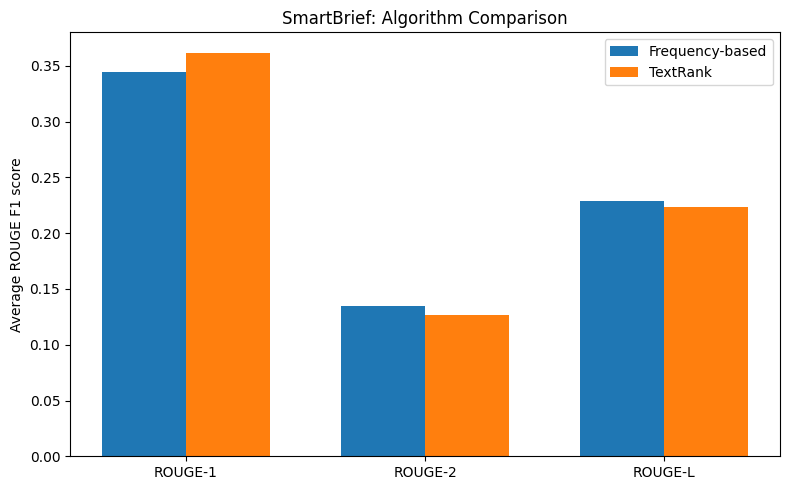

In [16]:
import matplotlib.pyplot as plt

metrics = ["ROUGE-1", "ROUGE-2", "ROUGE-L"]

frequency_scores = [
    comparison["Frequency ROUGE-1"].mean(),
    comparison["Frequency ROUGE-2"].mean(),
    comparison["Frequency ROUGE-L"].mean()
]

textrank_scores = [
    comparison["TextRank ROUGE-1"].mean(),
    comparison["TextRank ROUGE-2"].mean(),
    comparison["TextRank ROUGE-L"].mean()
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    frequency_scores,
    width,
    label="Frequency-based"
)

plt.bar(
    x + width / 2,
    textrank_scores,
    width,
    label="TextRank"
)

plt.xticks(x, metrics)
plt.ylabel("Average ROUGE F1 score")
plt.title("SmartBrief: Algorithm Comparison")
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
comparison.to_csv(
    "smartbrief_comparison_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [18]:
from google.colab import files

files.download("smartbrief_comparison_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>